<a href="https://colab.research.google.com/github/renatobdo/doutorado/blob/main/05_geracao_documentos_semanticos_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Título e objetivo

# Geração de documentos semânticos a partir dos óbitos por dengue no SIM

Este notebook transforma os registros estruturados do Sistema de Informações
sobre Mortalidade (SIM) em documentos semanticamente enriquecidos.

Cada documento representa um óbito cuja causa básica foi dengue e reúne:

1. identificador interno do registro;
2. data do óbito;
3. características demográficas;
4. localização de residência e ocorrência;
5. causa básica;
6. causas e condições registradas na Declaração de Óbito;
7. distinção entre Parte I e Parte II;
8. códigos e descrições da CID-10;
9. texto legível para recuperação semântica;
10. metadados de proveniência.

Os documentos produzidos poderão ser utilizados nas etapas de indexação,
recuperação semântica e geração de respostas explicáveis do sistema RAG.

2 - Importação das bibliotecas

In [ ]:
import os
import json
import re
import numpy as np
import pandas as pd



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


3. Definição dos caminhos

In [ ]:
BASE_DIR = (
    "/content/drive/MyDrive/Doutorado/"
    "arbovirus_rag"
)

CAMINHO_OBITOS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_reduzido.csv"
)

CAMINHO_CAUSAS = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_causas_cid10.csv"
)

CAMINHO_SAIDA_JSONL = os.path.join(
    BASE_DIR,
    "data_docs",
    "sim_obitos_dengue_2023_documentos_semanticos.jsonl"
)

CAMINHO_SAIDA_JSON = os.path.join(
    BASE_DIR,
    "data_docs",
    "sim_obitos_dengue_2023_documentos_semanticos.json"
)

CAMINHO_SAIDA_CSV = os.path.join(
    BASE_DIR,
    "data_processed",
    "sim_obitos_dengue_2023_documentos_semanticos.csv"
)

O formato principal será JSONL, no qual cada linha representa um documento.

4. Verificação dos arquivos

In [ ]:
arquivos_obrigatorios = [
    CAMINHO_OBITOS,
    CAMINHO_CAUSAS
]

for caminho in arquivos_obrigatorios:
    if not os.path.exists(caminho):
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho}"
        )

print("Todos os arquivos de entrada foram encontrados.")

Todos os arquivos de entrada foram encontrados.


5. Carregamento das bases

In [ ]:
df_obitos = pd.read_csv(
    CAMINHO_OBITOS,
    encoding="utf-8-sig",
    dtype="string"
)

df_causas = pd.read_csv(
    CAMINHO_CAUSAS,
    encoding="utf-8-sig",
    dtype="string"
)

print("Base de óbitos:")
print(df_obitos.shape)

print("\nBase de causas normalizadas:")
print(df_causas.shape)

Base de óbitos:
(1322, 16)

Base de causas:
(6266, 9)


6. Padronização do identificador

In [ ]:
df_obitos = df_obitos.reset_index(drop=True).copy()

if "ID_REGISTRO" not in df_obitos.columns:
    df_obitos.insert(
        0,
        "ID_REGISTRO",
        df_obitos.index + 1
    )
else:
    df_obitos["ID_REGISTRO"] = pd.to_numeric(
        df_obitos["ID_REGISTRO"],
        errors="raise"
    ).astype("int64")

df_causas["ID_REGISTRO"] = pd.to_numeric(
    df_causas["ID_REGISTRO"],
    errors="raise"
).astype("int64")

Validações

In [ ]:
if not df_obitos["ID_REGISTRO"].is_unique:
    raise ValueError(
        "ID_REGISTRO não é único na base de óbitos."
    )

ids_obitos = set(df_obitos["ID_REGISTRO"])
ids_causas = set(df_causas["ID_REGISTRO"])

ids_sem_correspondencia = ids_causas - ids_obitos

print(
    "IDs da base de causas sem correspondência:",
    len(ids_sem_correspondencia)
)

O esperado é:

0

Célula Markdown:

> `ID_REGISTRO` é um identificador interno criado para relacionar os arquivos
> processados. Ele não corresponde a um identificador oficial disponibilizado
> pelo SIM.

7. Funções auxiliares
7.1 Tratamento de valores ausentes

In [ ]:
def valor_ou_none(valor):
    """
    Converte valores ausentes ou vazios para None.
    """
    if pd.isna(valor):
        return None

    texto = str(valor).strip()

    if texto == "":
        return None

    if texto.lower() in {
        "nan",
        "none",
        "<na>"
    }:
        return None

    return texto

7.2 Conversão da data do óbito

A data do SIM pode aparecer como:

01012023

A função converte para:

2023-01-01

In [ ]:
def formatar_data_sim(valor):
    """
    Converte uma data no formato DDMMAAAA para AAAA-MM-DD.
    """
    valor = valor_ou_none(valor)

    if valor is None:
        return None

    texto = re.sub(r"\D", "", valor)

    if len(texto) != 8:
        return valor

    dia = texto[0:2]
    mes = texto[2:4]
    ano = texto[4:8]

    return f"{ano}-{mes}-{dia}"

7.3 Conversão da idade do SIM

In [ ]:
def converter_idade_sim(valor):
    """
    Converte o código de idade do SIM para uma estrutura legível.
    """
    valor = valor_ou_none(valor)

    if valor is None:
        return {
            "valor_original": None,
            "quantidade": None,
            "unidade": None,
            "idade_aproximada_anos": None
        }

    texto = str(valor).strip()

    if not texto.isdigit():
        return {
            "valor_original": texto,
            "quantidade": None,
            "unidade": None,
            "idade_aproximada_anos": None
        }

    codigo = int(texto)

    if codigo in {0, 999}:
        return {
            "valor_original": texto,
            "quantidade": None,
            "unidade": "ignorada",
            "idade_aproximada_anos": None
        }

    unidade_codigo = codigo // 100
    quantidade = codigo % 100

    unidades = {
        0: "minutos",
        1: "horas",
        2: "dias",
        3: "meses",
        4: "anos",
        5: "anos"
    }

    unidade = unidades.get(
        unidade_codigo,
        "não identificada"
    )

    if unidade_codigo == 0:
        idade_anos = quantidade / (
            60 * 24 * 365.25
        )

    elif unidade_codigo == 1:
        idade_anos = quantidade / (
            24 * 365.25
        )

    elif unidade_codigo == 2:
        idade_anos = quantidade / 365.25

    elif unidade_codigo == 3:
        idade_anos = quantidade / 12

    elif unidade_codigo in {4, 5}:
        idade_anos = float(quantidade)

    else:
        idade_anos = None

    if idade_anos is not None:
        idade_anos = round(idade_anos, 2)

    return {
        "valor_original": texto,
        "quantidade": quantidade,
        "unidade": unidade,
        "idade_aproximada_anos": idade_anos
    }

8. Mapeamentos categóricos
Sexo

In [ ]:
MAPA_SEXO = {
    "1": "Masculino",
    "2": "Feminino",
    "0": "Ignorado",
    "9": "Ignorado"
}

Raça/cor

In [ ]:
MAPA_RACA_COR = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indígena",
    "9": "Ignorada"
}

Tipo de óbito

In [ ]:
MAPA_TIPO_OBITO = {
    "1": "Óbito fetal",
    "2": "Óbito não fetal"
}

Local de ocorrência

In [ ]:
MAPA_LOCAL_OCORRENCIA = {
    "1": "Hospital",
    "2": "Outro estabelecimento de saúde",
    "3": "Domicílio",
    "4": "Via pública",
    "5": "Outros",
    "6": "Aldeia indígena",
    "9": "Ignorado"
}

9. Classificação da causa básica

In [ ]:
def classificar_tipo_dengue(codigo):
    """
    Classifica a causa básica entre A90 e A91.
    """
    codigo = valor_ou_none(codigo)

    if codigo is None:
        return None

    codigo = (
        codigo
        .upper()
        .replace("*", "")
        .replace(".", "")
    )

    if codigo.startswith("A90"):
        return "Dengue (A90)"

    if codigo.startswith("A91"):
        return "Dengue hemorrágica (A91)"

    return "Não classificado"

Aplicação

In [ ]:
df_obitos["TIPO_DENGUE"] = (
    df_obitos["CAUSABAS"]
    .apply(classificar_tipo_dengue)
)

Verificação

In [ ]:
df_obitos["TIPO_DENGUE"].value_counts(
    dropna=False
)

10. Preparação das causas por óbito

O arquivo de causas está em formato longitudinal. Vamos criar uma estrutura agrupada por óbito.

Primeiro, remova registros sem código:

In [ ]:
df_causas_validas = df_causas[
    df_causas["CODIGO_SIM"].notna()
].copy()

Ordene segundo a posição na declaração:

In [ ]:
ORDEM_CAMPO_CAUSA = {
    "CAUSABAS": 0,
    "LINHAA": 1,
    "LINHAB": 2,
    "LINHAC": 3,
    "LINHAD": 4,
    "LINHAII": 5
}

df_causas_validas["ORDEM_CAMPO"] = (
    df_causas_validas["CAMPO_CAUSA"]
    .map(ORDEM_CAMPO_CAUSA)
    .fillna(99)
)

In [ ]:
df_causas_validas = (
    df_causas_validas
    .sort_values(
        [
            "ID_REGISTRO",
            "ORDEM_CAMPO",
            "CODIGO_SIM"
        ]
    )
)

11. Função para estruturar as causas

In [ ]:
def construir_causas_obito(df_grupo):
    """
    Constrói a representação estruturada das causas
    registradas em um óbito.
    """

    causas_por_campo = {
        "CAUSABAS": [],
        "LINHAA": [],
        "LINHAB": [],
        "LINHAC": [],
        "LINHAD": [],
        "LINHAII": []
    }

    for _, linha in df_grupo.iterrows():

        campo = valor_ou_none(
            linha.get("CAMPO_CAUSA")
        )

        if campo not in causas_por_campo:
            continue

        causa = {
            "codigo": valor_ou_none(
                linha.get("CODIGO_SIM")
            ),
            "codigo_categoria": valor_ou_none(
                linha.get("CODIGO_CATEGORIA")
            ),
            "descricao": valor_ou_none(
                linha.get("DESCRICAO_CID")
            ),
            "papel": valor_ou_none(
                linha.get("PAPEL_CAUSA")
            ),
            "valor_original": valor_ou_none(
                linha.get("VALOR_ORIGINAL")
            )
        }

        causas_por_campo[campo].append(causa)

    return causas_por_campo

Crie um dicionário indexado por ID_REGISTRO:

In [ ]:
causas_por_id = {}

for id_registro, grupo in df_causas_validas.groupby(
    "ID_REGISTRO"
):
    causas_por_id[int(id_registro)] = (
        construir_causas_obito(grupo)
    )

Exemplo:

In [ ]:
primeiro_id = next(iter(causas_por_id))

causas_por_id[primeiro_id]

12. Separação entre Parte I e Parte II

In [ ]:
def obter_lista_causas(
    causas_por_campo,
    campos
):
    """
    Reúne as causas de uma lista de campos.
    """
    causas = []

    for campo in campos:
        causas.extend(
            causas_por_campo.get(campo, [])
        )

    return causas

Exemplo:

In [ ]:
causas_exemplo = causas_por_id[primeiro_id]

parte_i_exemplo = obter_lista_causas(
    causas_exemplo,
    [
        "LINHAA",
        "LINHAB",
        "LINHAC",
        "LINHAD"
    ]
)

parte_ii_exemplo = obter_lista_causas(
    causas_exemplo,
    ["LINHAII"]
)

display(parte_i_exemplo)
display(parte_ii_exemplo)

13. Remoção de duplicidades nas causas

O mesmo CID pode aparecer em mais de um campo. Para a lista consolidada, podemos remover duplicidades preservando a primeira ocorrência.

In [ ]:
def remover_causas_duplicadas(causas):
    """
    Remove códigos duplicados de uma lista de causas,
    preservando a primeira ocorrência.
    """
    causas_unicas = []
    codigos_vistos = set()

    for causa in causas:
        codigo = causa.get("codigo")

        if codigo is None:
            continue

        if codigo in codigos_vistos:
            continue

        codigos_vistos.add(codigo)
        causas_unicas.append(causa)

    return causas_unicas

14. Função para representar uma causa em texto

In [ ]:
def causa_para_texto(causa):
    """
    Retorna código e descrição em formato legível.
    """
    codigo = causa.get("codigo")
    descricao = causa.get("descricao")

    if codigo and descricao:
        return f"{codigo} — {descricao}"

    if descricao:
        return descricao

    if codigo:
        return codigo

    return None

15. Construção do texto semântico

O texto deve ser legível, objetivo e rastreável.

In [ ]:
def construir_texto_semantico(
    registro,
    causas_por_campo
):
    """
    Constrói uma representação textual de um óbito.
    """

    id_registro = int(
        registro["ID_REGISTRO"]
    )

    data_obito = formatar_data_sim(
        registro.get("DTOBITO")
    )

    tipo_dengue = valor_ou_none(
        registro.get("TIPO_DENGUE")
    )

    idade = converter_idade_sim(
        registro.get("IDADE")
    )

    sexo_codigo = valor_ou_none(
        registro.get("SEXO")
    )

    sexo = MAPA_SEXO.get(
        sexo_codigo,
        "Não informado"
    )

    raca_codigo = valor_ou_none(
        registro.get("RACACOR")
    )

    raca_cor = MAPA_RACA_COR.get(
        raca_codigo,
        "Não informada"
    )

    tipo_obito_codigo = valor_ou_none(
        registro.get("TIPOBITO")
    )

    tipo_obito = MAPA_TIPO_OBITO.get(
        tipo_obito_codigo,
        "Não informado"
    )

    local_codigo = valor_ou_none(
        registro.get("LOCOCOR")
    )

    local_ocorrencia = MAPA_LOCAL_OCORRENCIA.get(
        local_codigo,
        "Não informado"
    )

    causa_basica = causas_por_campo.get(
        "CAUSABAS",
        []
    )

    parte_i = obter_lista_causas(
        causas_por_campo,
        [
            "LINHAA",
            "LINHAB",
            "LINHAC",
            "LINHAD"
        ]
    )

    parte_ii = obter_lista_causas(
        causas_por_campo,
        ["LINHAII"]
    )

    parte_i = remover_causas_duplicadas(
        parte_i
    )

    parte_ii = remover_causas_duplicadas(
        parte_ii
    )

    partes_texto = []

    partes_texto.append(
        f"Registro interno {id_registro} do "
        f"Sistema de Informações sobre Mortalidade."
    )

    if data_obito:
        partes_texto.append(
            f"O óbito ocorreu em {data_obito}."
        )

    partes_texto.append(
        f"O registro foi classificado como "
        f"{tipo_obito.lower()}."
    )

    if tipo_dengue:
        partes_texto.append(
            f"A causa básica foi classificada como "
            f"{tipo_dengue}."
        )

    if causa_basica:
        textos_causa_basica = [
            causa_para_texto(causa)
            for causa in causa_basica
        ]

        textos_causa_basica = [
            texto
            for texto in textos_causa_basica
            if texto
        ]

        if textos_causa_basica:
            partes_texto.append(
                "Causa básica registrada: "
                + "; ".join(textos_causa_basica)
                + "."
            )

    perfil = []

    if idade["quantidade"] is not None:
        perfil.append(
            f"idade de {idade['quantidade']} "
            f"{idade['unidade']}"
        )

    if sexo != "Não informado":
        perfil.append(
            f"sexo {sexo.lower()}"
        )

    if raca_cor != "Não informada":
        perfil.append(
            f"raça/cor {raca_cor.lower()}"
        )

    if perfil:
        partes_texto.append(
            "Perfil demográfico: "
            + ", ".join(perfil)
            + "."
        )

    municipio_residencia = valor_ou_none(
        registro.get("CODMUNRES")
    )

    municipio_ocorrencia = valor_ou_none(
        registro.get("CODMUNOCOR")
    )

    localizacao = []

    if municipio_residencia:
        localizacao.append(
            "município de residência com código "
            f"{municipio_residencia}"
        )

    if municipio_ocorrencia:
        localizacao.append(
            "município de ocorrência com código "
            f"{municipio_ocorrencia}"
        )

    if local_ocorrencia != "Não informado":
        localizacao.append(
            f"local de ocorrência: "
            f"{local_ocorrencia.lower()}"
        )

    if localizacao:
        partes_texto.append(
            "Informações de localização: "
            + "; ".join(localizacao)
            + "."
        )

    textos_parte_i = [
        causa_para_texto(causa)
        for causa in parte_i
    ]

    textos_parte_i = [
        texto
        for texto in textos_parte_i
        if texto
    ]

    if textos_parte_i:
        partes_texto.append(
            "Na Parte I da Declaração de Óbito, "
            "correspondente à sequência causal, "
            "foram registradas as condições: "
            + "; ".join(textos_parte_i)
            + "."
        )

    textos_parte_ii = [
        causa_para_texto(causa)
        for causa in parte_ii
    ]

    textos_parte_ii = [
        texto
        for texto in textos_parte_ii
        if texto
    ]

    if textos_parte_ii:
        partes_texto.append(
            "Na Parte II da Declaração de Óbito, "
            "foram registradas as condições "
            "contribuintes: "
            + "; ".join(textos_parte_ii)
            + "."
        )

    estabelecimento_codigo = valor_ou_none(
        registro.get("CODESTAB")
    )

    estabelecimento_nome = valor_ou_none(
        registro.get("ESTABDESCR")
    )

    if estabelecimento_codigo or estabelecimento_nome:
        partes_estabelecimento = []

        if estabelecimento_nome:
            partes_estabelecimento.append(
                estabelecimento_nome
            )

        if estabelecimento_codigo:
            partes_estabelecimento.append(
                f"CNES {estabelecimento_codigo}"
            )

        partes_texto.append(
            "Estabelecimento relacionado ao registro: "
            + ", ".join(partes_estabelecimento)
            + "."
        )

    return " ".join(partes_texto)

16. Construção do documento estruturado

In [ ]:
def construir_documento_semantico(
    registro,
    causas_por_campo
):
    """
    Cria um documento semântico estruturado
    correspondente a um óbito.
    """

    id_registro = int(
        registro["ID_REGISTRO"]
    )

    idade = converter_idade_sim(
        registro.get("IDADE")
    )

    sexo_codigo = valor_ou_none(
        registro.get("SEXO")
    )

    raca_codigo = valor_ou_none(
        registro.get("RACACOR")
    )

    tipo_obito_codigo = valor_ou_none(
        registro.get("TIPOBITO")
    )

    local_codigo = valor_ou_none(
        registro.get("LOCOCOR")
    )

    parte_i = remover_causas_duplicadas(
        obter_lista_causas(
            causas_por_campo,
            [
                "LINHAA",
                "LINHAB",
                "LINHAC",
                "LINHAD"
            ]
        )
    )

    parte_ii = remover_causas_duplicadas(
        obter_lista_causas(
            causas_por_campo,
            ["LINHAII"]
        )
    )

    causas_associadas = remover_causas_duplicadas(
        parte_i + parte_ii
    )

    documento = {
        "document_id": (
            f"SIM_OBITO_DENGUE_2023_"
            f"{id_registro:06d}"
        ),

        "document_type": (
            "sim_obito_dengue_semantic_document"
        ),

        "source": {
            "system": "SIM",
            "system_name": (
                "Sistema de Informações "
                "sobre Mortalidade"
            ),
            "year": 2023,
            "dataset": "DOBR2023",
            "processing_stage": (
                "normalizado_e_enriquecido_cid10"
            )
        },

        "record": {
            "id_registro_interno": id_registro,
            "data_obito": formatar_data_sim(
                registro.get("DTOBITO")
            ),
            "tipo_obito": {
                "codigo": tipo_obito_codigo,
                "descricao": MAPA_TIPO_OBITO.get(
                    tipo_obito_codigo,
                    "Não informado"
                )
            }
        },

        "patient_profile": {
            "age": idade,
            "sex": {
                "codigo": sexo_codigo,
                "descricao": MAPA_SEXO.get(
                    sexo_codigo,
                    "Não informado"
                )
            },
            "race_color": {
                "codigo": raca_codigo,
                "descricao": MAPA_RACA_COR.get(
                    raca_codigo,
                    "Não informada"
                )
            }
        },

        "location": {
            "municipality_residence_code": (
                valor_ou_none(
                    registro.get("CODMUNRES")
                )
            ),
            "municipality_occurrence_code": (
                valor_ou_none(
                    registro.get("CODMUNOCOR")
                )
            ),
            "occurrence_place": {
                "codigo": local_codigo,
                "descricao": (
                    MAPA_LOCAL_OCORRENCIA.get(
                        local_codigo,
                        "Não informado"
                    )
                )
            }
        },

        "health_establishment": {
            "cnes_code": valor_ou_none(
                registro.get("CODESTAB")
            ),
            "name": valor_ou_none(
                registro.get("ESTABDESCR")
            )
        },

        "death_causes": {
            "basic_cause_type": valor_ou_none(
                registro.get("TIPO_DENGUE")
            ),
            "basic_cause": causas_por_campo.get(
                "CAUSABAS",
                []
            ),
            "part_i": {
                "description": (
                    "Sequência causal registrada "
                    "na Declaração de Óbito"
                ),
                "line_a": causas_por_campo.get(
                    "LINHAA",
                    []
                ),
                "line_b": causas_por_campo.get(
                    "LINHAB",
                    []
                ),
                "line_c": causas_por_campo.get(
                    "LINHAC",
                    []
                ),
                "line_d": causas_por_campo.get(
                    "LINHAD",
                    []
                ),
                "all_conditions": parte_i
            },
            "part_ii": {
                "description": (
                    "Condições contribuintes "
                    "registradas na Parte II"
                ),
                "conditions": parte_ii
            },
            "associated_conditions": (
                causas_associadas
            )
        },

        "semantic_metadata": {
            "disease": "Dengue",
            "disease_group": "Arbovirose",
            "classification_system": "CID-10",
            "basic_cause_code": valor_ou_none(
                registro.get("CAUSABAS")
            ),
            "basic_cause_category": (
                valor_ou_none(
                    registro.get("CAUSABAS")
                )[:3]
                if valor_ou_none(
                    registro.get("CAUSABAS")
                )
                else None
            ),
            "total_part_i_conditions": len(
                parte_i
            ),
            "total_part_ii_conditions": len(
                parte_ii
            ),
            "total_associated_conditions": len(
                causas_associadas
            )
        },

        "provenance": {
            "source_system": "SIM",
            "source_file": "DOBR2023.dbc",
            "processed_input_file": (
                "sim_obitos_dengue_2023_"
                "reduzido.csv"
            ),
            "cid_reference": "CID-10",
            "id_notice": (
                "ID_REGISTRO é um identificador "
                "interno criado para processamento "
                "e não corresponde a um identificador "
                "oficial do SIM."
            )
        }
    }

    documento["text"] = construir_texto_semantico(
        registro,
        causas_por_campo
    )

    return documento

17. Geração de todos os documentos

In [ ]:
documentos_semanticos = []

for _, registro in df_obitos.iterrows():

    id_registro = int(
        registro["ID_REGISTRO"]
    )

    causas_registro = causas_por_id.get(
        id_registro,
        {
            "CAUSABAS": [],
            "LINHAA": [],
            "LINHAB": [],
            "LINHAC": [],
            "LINHAD": [],
            "LINHAII": []
        }
    )

    documento = construir_documento_semantico(
        registro,
        causas_registro
    )

    documentos_semanticos.append(
        documento
    )

print(
    "Documentos semânticos gerados:",
    len(documentos_semanticos)
)

O esperado é obter aproximadamente:

1322

18. Visualização de um documento

In [ ]:
print(
    json.dumps(
        documentos_semanticos[0],
        ensure_ascii=False,
        indent=2
    )
)

Uma estrutura resumida será semelhante a:
{
  "document_id": "SIM_OBITO_DENGUE_2023_000001",
  "document_type": "sim_obito_dengue_semantic_document",
  "source": {
    "system": "SIM",
    "year": 2023
  },
  "record": {
    "id_registro_interno": 1,
    "data_obito": "2023-01-01"
  },
  "patient_profile": {
    "age": {
      "quantidade": 71,
      "unidade": "anos"
    },
    "sex": {
      "descricao": "Feminino"
    }
  },
  "death_causes": {
    "basic_cause_type": "Dengue hemorrágica (A91)",
    "part_i": {
      "all_conditions": [
        {
          "codigo": "R571",
          "descricao": "Choque hipovolêmico"
        }
      ]
    },
    "part_ii": {
      "conditions": [
        {
          "codigo": "I10X",
          "descricao": "Hipertensão essencial"
        }
      ]
    }
  },
  "text": "Registro interno 1 do Sistema de Informações sobre Mortalidade..."
}

19. Visualização apenas do texto

In [ ]:
print(
    documentos_semanticos[0]["text"]
)

Exemplo:
Registro interno 1 do Sistema de Informações sobre Mortalidade.
O óbito ocorreu em 2023-01-01. O registro foi classificado como
óbito não fetal. A causa básica foi classificada como dengue
hemorrágica (A91). Causa básica registrada: A91 — Dengue
hemorrágica. Perfil demográfico: idade de 71 anos, sexo feminino,
raça/cor branca. Na Parte I da Declaração de Óbito, correspondente
à sequência causal, foram registradas as condições:
R571 — Choque hipovolêmico; N179 — Insuficiência renal aguda.
Na Parte II foram registradas as condições contribuintes:
I10X — Hipertensão essencial.

20. Validação dos documentos

IDs únicos

In [ ]:
ids_documentos = [
    documento["document_id"]
    for documento in documentos_semanticos
]

assert len(ids_documentos) == len(
    set(ids_documentos)
)

print("Todos os document_id são únicos.")

Quantidade de documentos

In [ ]:
assert (
    len(documentos_semanticos)
    == df_obitos["ID_REGISTRO"].nunique()
)

print(
    "A quantidade de documentos corresponde "
    "à quantidade de óbitos."
)

Documentos sem texto

In [ ]:
documentos_sem_texto = [
    documento
    for documento in documentos_semanticos
    if not documento.get("text")
]

print(
    "Documentos sem texto:",
    len(documentos_sem_texto)
)

Documentos sem causa básica

In [ ]:
documentos_sem_causa_basica = [
    documento
    for documento in documentos_semanticos
    if not documento[
        "death_causes"
    ]["basic_cause"]
]

print(
    "Documentos sem causa básica:",
    len(documentos_sem_causa_basica)
)

21. Conversão para DataFrame

Para inspeção e futura indexação:

In [ ]:
registros_dataframe = []

for documento in documentos_semanticos:

    causas_associadas = documento[
        "death_causes"
    ]["associated_conditions"]

    codigos_associados = [
        causa.get("codigo")
        for causa in causas_associadas
        if causa.get("codigo")
    ]

    descricoes_associadas = [
        causa.get("descricao")
        for causa in causas_associadas
        if causa.get("descricao")
    ]

    registro = {
        "DOCUMENT_ID": documento[
            "document_id"
        ],

        "ID_REGISTRO": documento[
            "record"
        ]["id_registro_interno"],

        "DATA_OBITO": documento[
            "record"
        ]["data_obito"],

        "TIPO_DENGUE": documento[
            "death_causes"
        ]["basic_cause_type"],

        "SEXO": documento[
            "patient_profile"
        ]["sex"]["descricao"],

        "RACA_COR": documento[
            "patient_profile"
        ]["race_color"]["descricao"],

        "IDADE_ANOS": documento[
            "patient_profile"
        ]["age"]["idade_aproximada_anos"],

        "CODMUNRES": documento[
            "location"
        ]["municipality_residence_code"],

        "CODMUNOCOR": documento[
            "location"
        ]["municipality_occurrence_code"],

        "CODIGOS_ASSOCIADOS": "; ".join(
            codigos_associados
        ),

        "DESCRICOES_ASSOCIADAS": "; ".join(
            descricoes_associadas
        ),

        "TOTAL_CAUSAS_ASSOCIADAS": documento[
            "semantic_metadata"
        ]["total_associated_conditions"],

        "TEXTO": documento["text"]
    }

    registros_dataframe.append(registro)

df_documentos_semanticos = pd.DataFrame(
    registros_dataframe
)

Visualização:

In [ ]:
df_documentos_semanticos.head()

22. Salvamento em JSONL

O JSONL é especialmente adequado para processamento em lotes.

In [ ]:
with open(
    CAMINHO_SAIDA_JSONL,
    "w",
    encoding="utf-8"
) as arquivo:

    for documento in documentos_semanticos:
        linha_json = json.dumps(
            documento,
            ensure_ascii=False
        )

        arquivo.write(
            linha_json + "\n"
        )

print(
    "Arquivo JSONL salvo em:\n"
    f"{CAMINHO_SAIDA_JSONL}"
)

23. Salvamento em JSON

Esse formato mantém todos os documentos em uma lista.

In [ ]:
with open(
    CAMINHO_SAIDA_JSON,
    "w",
    encoding="utf-8"
) as arquivo:

    json.dump(
        documentos_semanticos,
        arquivo,
        ensure_ascii=False,
        indent=2
    )

print(
    "Arquivo JSON salvo em:\n"
    f"{CAMINHO_SAIDA_JSON}"
)

24. Salvamento em CSV

In [ ]:
df_documentos_semanticos.to_csv(
    CAMINHO_SAIDA_CSV,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Arquivo CSV salvo em:\n"
    f"{CAMINHO_SAIDA_CSV}"
)

25. Leitura de teste do JSONL

In [ ]:
documentos_teste = []

with open(
    CAMINHO_SAIDA_JSONL,
    "r",
    encoding="utf-8"
) as arquivo:

    for numero_linha, linha in enumerate(
        arquivo
    ):
        documentos_teste.append(
            json.loads(linha)
        )

        if numero_linha == 4:
            break

print(
    f"{len(documentos_teste)} documentos "
    f"lidos para validação."
)

In [ ]:
print(
    documentos_teste[0]["text"]
)

26. Resumo final

In [ ]:
total_documentos = len(
    documentos_semanticos
)

total_a90 = sum(
    documento["death_causes"][
        "basic_cause_type"
    ] == "Dengue (A90)"
    for documento in documentos_semanticos
)

total_a91 = sum(
    documento["death_causes"][
        "basic_cause_type"
    ] == "Dengue hemorrágica (A91)"
    for documento in documentos_semanticos
)

total_com_parte_i = sum(
    len(
        documento["death_causes"][
            "part_i"
        ]["all_conditions"]
    ) > 0
    for documento in documentos_semanticos
)

total_com_parte_ii = sum(
    len(
        documento["death_causes"][
            "part_ii"
        ]["conditions"]
    ) > 0
    for documento in documentos_semanticos
)

print("=" * 70)
print("RESUMO DA GERAÇÃO DE DOCUMENTOS SEMÂNTICOS")
print("=" * 70)

print(
    f"Documentos gerados: "
    f"{total_documentos:,}"
)

print(
    f"Documentos classificados como A90: "
    f"{total_a90:,}"
)

print(
    f"Documentos classificados como A91: "
    f"{total_a91:,}"
)

print(
    f"Documentos com condições na Parte I: "
    f"{total_com_parte_i:,}"
)

print(
    f"Documentos com condições na Parte II: "
    f"{total_com_parte_ii:,}"
)

print(
    f"JSONL: {CAMINHO_SAIDA_JSONL}"
)

print(
    f"JSON: {CAMINHO_SAIDA_JSON}"
)

print(
    f"CSV: {CAMINHO_SAIDA_CSV}"
)

Estrutura conceitual do documento

Cada documento terá quatro níveis principais:

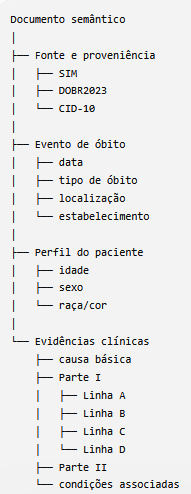

Documento semântico versus evidência semântica

Essa distinção pode ser útil para a sua ontologia:

Documento semântico: representa o registro completo do óbito;
Evidência semântica: representa uma informação específica extraída desse documento.

Por exemplo:

Documento semântico:
Óbito SIM 2023 — registro interno 125

Evidência semântica 1:
A causa básica foi dengue hemorrágica.

Evidência semântica 2:
Choque hipovolêmico apareceu na Linha A.

Evidência semântica 3:
Hipertensão foi registrada na Parte II.

Nesta primeira versão, o notebook gera um documento completo por óbito. No próximo passo, esses documentos poderão ser divididos em evidências menores para indexação, recuperação e explicação das respostas.